In [ ]:
import sympy as sp 
import numpy as np
import matplotlib.pyplot as plt


: 

## Equations différentielles Ordinaires d'ordre p 
On peut parfois écrire une équation différentielle ordinaire d'ordre de p $\in$ $\mathbb{N_+}$ comme une équation d'ordre 1:

$x^{(p)} + a_{p-1}x^{(p-1)} + \dots + a_1 x' + a_0 x = f(x)$ dans certains cas il  existe $F:\mathbb{K}^n \rightarrow \mathbb{K}^n$ telle que ${X'(t)} = F({X(t)})$ $F$ est appellée un champ de vecteur autonome.

${X(t)} = \begin{pmatrix} \overset{(1)\hspace{-5pt}}{x} \\ ... \\ \overset{(p-1)\hspace{-5pt}}{x}\end{pmatrix}$


### Equations différentielles affines
Nous allons commencer par traiter les équations différentielles affines du premier ordre de la forme ${X'(t)} = A(t){X(t)} + {B(t)}$  $\small{(2)}$

avec ${A(.)} \in  M_n(\mathbb{K})$ et ${X(t)}, {B(.)} \in \mathbb{K}^n$ 

#### Equations différentielles linéaires autonomes
Ce sont des cas particulier de $(2)$ où l'application linéaire ${A(.)}$ est constante et ${B(.)}=0$

On a l'équation suivante ${X'(t)} = A{X(t)}$. 

Un exemple serait un circuit RLC, l'équation canonique est  $$\frac{d^2 {U_c}}{dt^2} + RC \frac{d {U_c}}{dt} + \frac{1}{LC}{U_c} = 0$$

On a donc la relation suivante $${X'(t)}= \begin{pmatrix} \frac{d{U_c}}{dt} \\ \frac{d²{U_c}}{dt²}  \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ -\frac{1}{LC} & -\frac{R}{L} \end{pmatrix} \begin{pmatrix} {U_c} \\ \frac{d{U_c}}{dt}  \end{pmatrix} $$

In [ ]:
r,c,l =sp.symbols("R,C,L")
t,uc = sp.symbols("t,Uc")
uc0,duc0 = sp.symbols("Uc_0,Uc'")
A = sp.Matrix([[0,1],[-1/(c*l),-r/l ]])
sp.init_printing()

A



⎡ 0    1 ⎤
⎢        ⎥
⎢-1   -R ⎥
⎢───  ───⎥
⎣C⋅L   L ⎦

Maintenant on va essayer de résoudre cela en diagonalisant la matrice $A$, ce qu'on va faire c'est un changement de base pour se ramener à une matrice diagonale.

$A = P^{-1} D P$ le système est maintenant équivalent à ${PX'(t)} = DP{X(t)}$ ainsi en posant $ Y(t) = PX(t) \iff Y'(t) = DY(t)$ le système devient très simple à résoudre, en effet les solutions seront : $$Y(t) = \begin{pmatrix} e^{\lambda}y_1(0) \\ e^{\mu}y_1(0)  \end{pmatrix}$$ où $\lambda$ et $\mu$ sont les valeurs propres de $D$

Ensuite il nous restera juste à multiplier $Y(t)$ par la matrice de passage $P^{-1}$

In [ ]:
P,D =A.diagonalize()
P_inv =P.inv()

lambd, mu = D[0,0],D[1,1]
#Calcul de y0
y0 = P_inv*sp.Matrix([[uc0],[duc0]])

#Solution dans la base du changement
M = sp.Matrix([[sp.exp(lambd*t),0],[0,sp.exp(mu*t)]])

#Retour dans la base initiale
X = sp.simplify(P*M*y0)
duc = sp.simplify(X[1])
uc = sp.simplify(X[0])

⎡   ⎛           ________________⎞                                  ⎤
⎢   ⎜          ╱   ⎛   2      ⎞ ⎟                                  ⎥
⎢   ⎜   R    ╲╱  C⋅⎝C⋅R  - 4⋅L⎠ ⎟                                  ⎥
⎢ t⋅⎜- ─── - ───────────────────⎟                                  ⎥
⎢   ⎝  2⋅L          2⋅C⋅L       ⎠                                  ⎥
⎢ℯ                                                0                ⎥
⎢                                                                  ⎥
⎢                                     ⎛           ________________⎞⎥
⎢                                     ⎜          ╱   ⎛   2      ⎞ ⎟⎥
⎢                                     ⎜   R    ╲╱  C⋅⎝C⋅R  - 4⋅L⎠ ⎟⎥
⎢                                   t⋅⎜- ─── + ───────────────────⎟⎥
⎢                                     ⎝  2⋅L          2⋅C⋅L       ⎠⎥
⎣               0                  ℯ                               ⎦

Cas $(\frac{R}{L})² - \frac{4}{LC} > 0$:

In [ ]:
values = {c:1e-7,l:1e-4,uc0:1,duc0:0,r:1000}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)
print(delta.subs(values))
#plot
time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]
plt.plot(time,uc_t)

duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
plt.plot(uc_t,duc_t)
plt.show()

NameError: name 'c' is not defined

Espace des phases

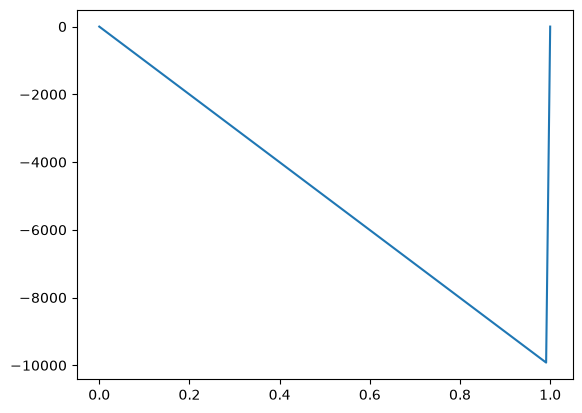

In [ ]:
duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
plt.plot(uc_t,duc_t)
plt.show()

Cas $(\frac{R}{L})² - \frac{4}{LC} < 0$:

-30000000000.0000


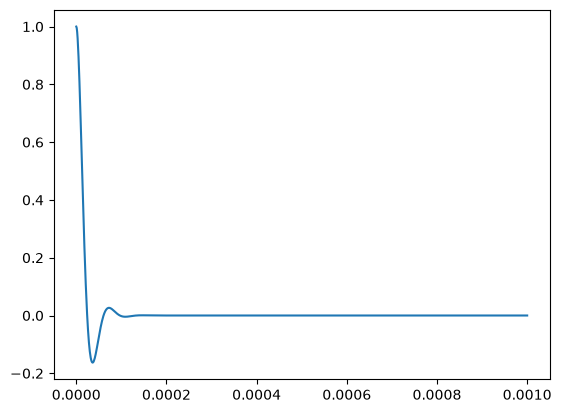

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:100}
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)
print(delta.subs(values))
#plot
time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]
plt.plot(time,uc_t)
plt.show()

Espace des phases

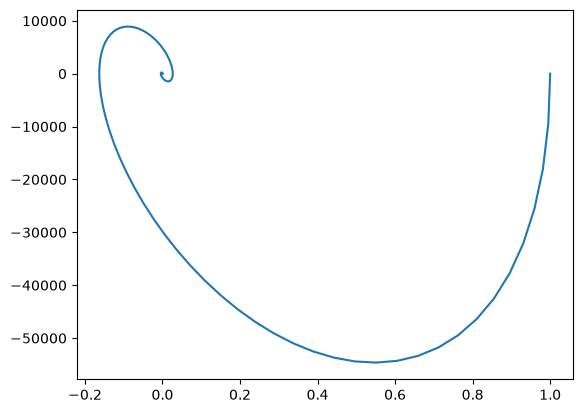

In [ ]:
duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
plt.plot(uc_t,duc_t)
plt.show()

Cas $(\frac{R}{L})² - \frac{4}{LC} = 0$:


0


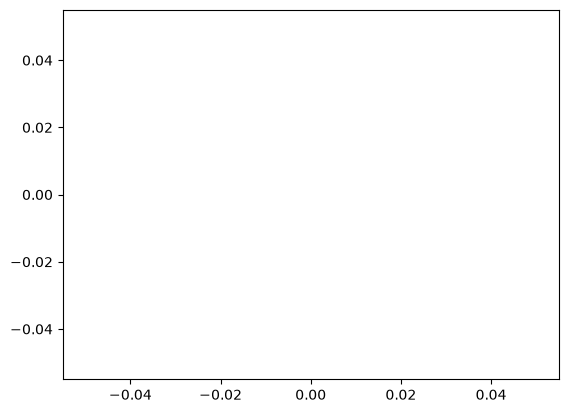

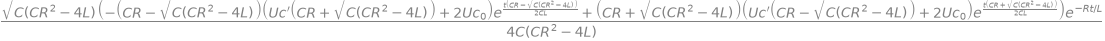

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:2e2}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)
print(delta.subs(values))
#plot
time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]
plt.plot(time,uc_t)
plt.show()
uc

Espaces de phases

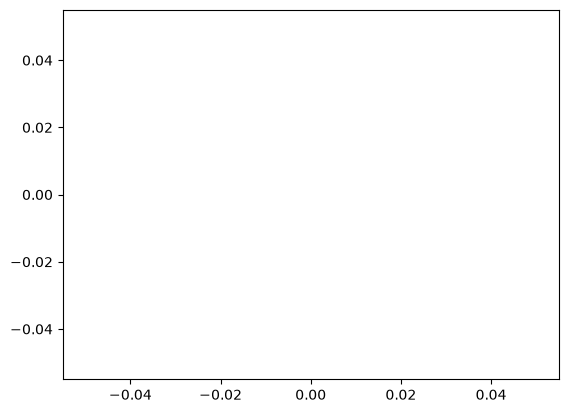

In [ ]:
duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
plt.plot(uc_t,duc_t)
plt.show()

### Equations différentielles générales 
$${X(t)} = F({X(t)})$$ Prenons le cas du système de Lotka Volterra: $$F(x,y) = \begin{pmatrix} x(y-1) \\ y(1-x) \end{pmatrix}$$

/tmp/ipykernel_39808/701403659.py:7: RuntimeWarning: invalid value encountered in divide
  U_norm = U/norm
/tmp/ipykernel_39808/701403659.py:8: RuntimeWarning: invalid value encountered in divide
  V_norm = V/norm


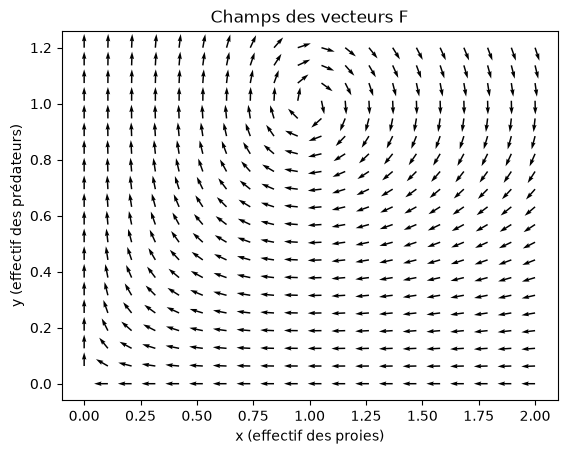

In [ ]:
x = np.linspace(0,2,20)
y = np.linspace(0,1.2,20)
X,Y = np.meshgrid(x,y)
U = X*(Y-1)
V = Y*(1-X)
norm = np.sqrt(U**2+V**2)
U_norm = U/norm
V_norm = V/norm
scale = 1

plt.quiver(X,Y,U_norm*scale, V_norm*scale,color = "black")
plt.title("Champs des vecteurs F")
plt.xlabel("x (effectif des proies)")
plt.ylabel("y (effectif des prédateurs)")
plt.show()

<!-- Basic operations -->
$+$, $-$, $\times$, $\div$, $\pm$, $\mp$

<!-- Relational operations -->
$=$, $\neq$, $<$, $>$, $\leq$, $\geq$, $\ll$, $\gg$

<!-- Logical operations -->
$\land$, $\lor$, $\lnot$, $\implies$, $\iff$

<!-- Set operations -->
$\in$, $\notin$, $\subset$, $\supset$, $\cup$, $\cap$, $\emptyset$

<!-- Other symbols -->
$\infty$, $\partial$, $\nabla$, $\propto$, $\approx$, $\equiv$